In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from helpers.OpticsDataLoader import *
import helpers.MathEquations as ME
from helpers.PhotonInfo import * # this calls DataLoader when defining init
from helpers.PNJunction import *
import helpers.PDEStyle as MS

rad2deg = 180/np.pi

# MS.ShowMyStyles() # for colors
# ms = MS.MyStyleSet() # object to use like
# ms.SetMPLcolors() # turn off with "off" option


In [2]:
file_path = "../veraData/HPK_IR_PDE-Feb12_2024-Harry.csv"
df = pd.read_csv(file_path, header=0)

# print(df)
# print(df.info())
print(df.head())
print("--------------------------")

print(df['Overvoltage'].value_counts())
print(df['Angle'].value_counts())

angles = df['Angle'].unique()
voltages = df['Overvoltage'].unique()

# print("Angles:", angles)
# print("voltages:", voltages)



   Wavelength  Angle  Overvoltage  Responsivity  PDE  PDE_error
0       0.000      0            0  0.000000e+00  0.0        0.0
1     349.999      0            0  1.318470e-17  inf        0.0
2     359.978      0            0  1.303360e-17  inf        0.0
3     369.959      0            0  1.342020e-17  inf        0.0
4     380.000      0            0  1.444730e-17  inf        0.0
--------------------------
Overvoltage
0    260
1    255
2    255
3    255
4    255
5    255
6    254
7    204
8    200
Name: count, dtype: int64
Angle
0     459
15    459
30    459
45    459
60    357
Name: count, dtype: int64


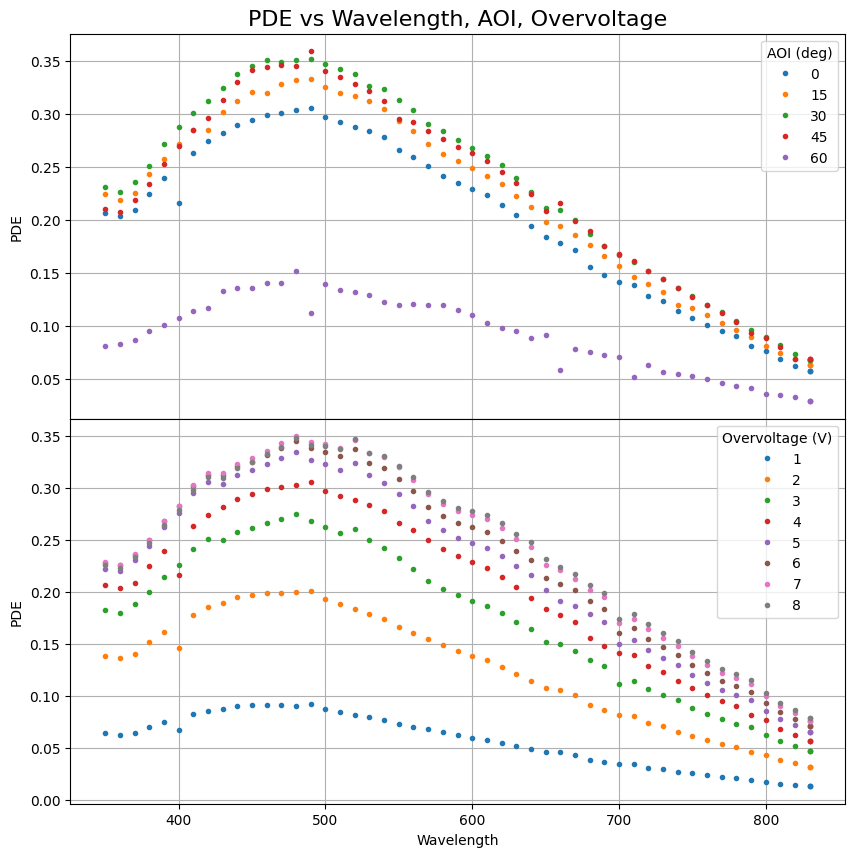

In [3]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize = (10, 10))

# xv4 = df[df['Overvoltage'] == 4]
for angle in angles:
    dt1 = df[(df['Angle'] == angle) & (df['Overvoltage'] == 4)]

    dt1.plot(x='Wavelength', y = "PDE", label = f"{angle:0.0f}", linestyle = "", marker = ".", ax = ax1)
    
ax1.legend(title = "AOI (deg)")
ax1.set_ylabel("PDE")

for voltage in voltages[1:]:
    dt2 = df[(df['Angle'] == 0) & (df['Overvoltage'] == voltage)]
    dt2.plot(x='Wavelength', y = "PDE", label = f"{voltage:0.0f}", linestyle = "", marker = ".", ax = ax2)

ax2.legend(title = "Overvoltage (V)")
ax2.set_ylabel("PDE")

ax1.grid(), ax2.grid()
ax1.set_title("PDE vs Wavelength, AOI, Overvoltage", fontsize = 16)
plt.subplots_adjust(hspace=0)
plt.show()

# matrix

In [4]:
## PDE 'master' function

def PDE_allArgs(wlen, theta1, FF, tOxide, dp_star, Xpn, dw_star, pe, ph):
    photon = PhotonInfo(wlen, theta1)    
    Ttotal = photon.Wave_TotalTransmission(tOxide)
    pn = PNJunction(tOxide = tOxide, dp_star = dp_star, Xpn = Xpn, dw_star=dw_star, pe = pe, ph = ph)
    Wp, Wn = pn.calcW_both(photon)
    return FF * Ttotal * (Wp*pe + Wn*ph)

# def StandardPDE(FF, T, Wp, Wn, Pe, Ph):
#     return FF * T * (Wp*Pe + Wn*Ph)

# def FullPDE_fromObjects(PNInfo, PhotonInfo):
#     Wp, Wn = PNInfo.calcW_both(PhotonInfo)
#     T = PhotonInfo.Wave_TotalTransmission(PNInfo)
#     return StandardPDE(FF=PNInfo.FF, T=T, Wp=Wp, Wn=Wn, Pe=PNInfo.pE, Ph=PNInfo.ph)

---
## PDE fitting v1
still defining PDE equations locally. There are different ways to minimize this and/or create a score statistic

1. least squares
1. chi2 (error!?)


### Coding Strategies
To have control, there are *at least* three methods without resorting to pyroot or something more exotic than scipy
1. wrap the PDE functions with other functions (hard to control other params, need to pass a dict)
2. curve_fit with very small bounds on the 'fixed' parameters. maybe clearest and simplest
3. the dictionairy sorting method done below. confusing but possibly most robust/user friendly if coded properly

In [5]:
from scipy.optimize import minimize
from scipy.optimize import curve_fit

# I hate writing these manual wrappers
# need format (xVals, parametersToFit, fixedParameters)

# get the list of keys needed to call PDE_allArgs, based off what is in wrapper function
# and check if what is needed exists in the givenDict
def checkParams_inWrapper(fInside, fGlobal, givenDict):
    argsInside = fInside.__code__.co_varnames[:fInside.__code__.co_argcount]
    argsGlobal = list(fGlobal.__code__.co_varnames[:fGlobal.__code__.co_argcount])
    argsMissing = [arg for arg in argsGlobal if arg not in argsInside]
    if not all(key in givenDict for key in argsMissing): # check that all needed keys are in givenDict
        print(f"Error in {fInside.__name__}: - Not all keys in dArgs, \n given: {givenDict} \n needed: {argsMissing}")
        return False
    return argsMissing

def orderDict(func, givenDict): # get the dictionary in the order needed for the function
    argsInside = func.__code__.co_varnames[:func.__code__.co_argcount]
    return {key: givenDict[key] for key in argsInside if key in givenDict}

###---------- Wrapped PDE functions ------------###
fixedFF = 0.6
staticPars = {"FF":0.6, "theta1":0.0, "dp_star": 4, "Xpn": 2e3, "tOxide": 110, "dw_star": 5e3, "pe": 0.5, "ph": 0.5}

### UV: 350-450 nm
# free:            pe, dp*, tOxide
# medium (free):   Xpn
# insensitive (fixed):  dw*, ph

# dArgs: dw_star, ph       theta1, FF
def PDE_wrapped_uv(wlen, tOxide, dp_star, Xpn, pe):
    if not (missingArgs := checkParams_inWrapper(PDE_wrapped_uv, PDE_allArgs, staticPars)):
        return False
    newDict = {key: staticPars[key] for key in missingArgs}
    return PDE_allArgs(wlen, tOxide=tOxide, dp_star=dp_star, Xpn=Xpn, pe=pe, **newDict)

### Vis: 450-800 nm
# free:                 ph, dw_star, tOxide
# medium (free):        Xpn
# insensitive (fixed):  dp*, pe

# dArgs: dp*, pe       theta1, FF
def PDE_wrapped_vis(wlen, tOxide, Xpn, dw_star, ph):
    if not (missingArgs := checkParams_inWrapper(PDE_wrapped_vis, PDE_allArgs, staticPars)): # get list of missing args. check we have everything needed
        return False
    newDict = {key: staticPars[key] for key in missingArgs}
    return PDE_allArgs(wlen, tOxide=tOxide, Xpn=Xpn, dw_star=dw_star, ph=ph, **newDict)

# def PDE_mostPars(wlen, tOxide, dp_star, Xpn, dw_star, pe, ph):
#     FF = staticPars["FF"]
#     theta = staticPars["theta"]
#     return PDE_allArgs(wlen, theta, FF, tOxide, dp_star, Xpn, dw_star, pe, ph)

PDE_wrapped_uv(*(450, 110, 4, 2e3, 0.5))


-----------------------------
Silicon data from
   opticsData/silicon_crystalline-lithography.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   opticsData/silicon_oxide-lithography-UV.txt
loaded and interpolated successfully.
-----------------------------


0.19157971451422304

NameError: name 'dfit_fixed_UV' is not defined

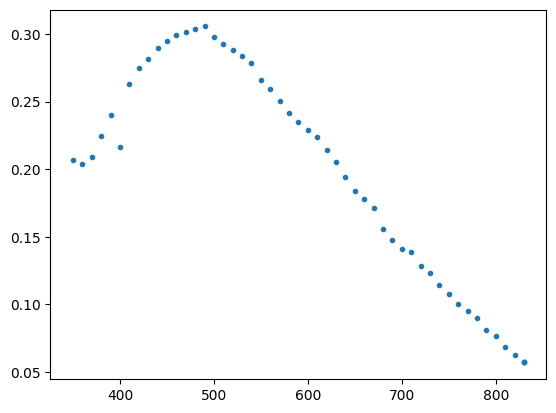

In [6]:


# --------------------------------- #
## test PN Junction ##
pn = PNJunction(tOxide = 110, dp_star = 4, dp = 5)
pn.pe = 0.6
pn.ph = 0.0

fitAngle = 0
voltages = df['Overvoltage'].unique()[2:]
for V in voltages[2:3]:
    df_fit = df[(df['Angle'] == fitAngle) & (df['Overvoltage'] == V)]
    xData = df_fit['Wavelength']
    yData = df_fit['PDE']
    plt.plot(xData, yData, marker = ".", linestyle = "", label = f"{V:0.0f}V")

# input dictionary and reorder to fit function
dfit = {"tOxide": 90, "dp_star": 2, "Xpn": 1.5e3, "dw_star": 3e3, "pe": 0.65, "ph":0.1, "theta1": 0.0, "FF": 0.6}
dfit = orderDict(PDE_allArgs, dfit)

delta = 1e-6
bounds_dict = {"tOxide":(50, 500), "dp_star":(0.5, 50), "Xpn":(1e3, 1e5), "dw_star":(3e3, 3e3+delta),
               "pe":(0.0, 1.0), "ph":(0.1, 0.1+delta),
               "theta1": (0, 0+delta), "FF": (0.6, 0.6+delta)}


pOtherArgs = tuple(dfit_fixed_UV.values())
pGuess = tuple(dfit_float_UV.values())
lower_bounds = [bounds_dict[key][0] for key in dfit_float_UV]
upper_bounds = [bounds_dict[key][1] for key in dfit_float_UV]

yUV_guess = PDE_wrapped_uv(xData, **dfit_float_UV, dArgs = dfit_fixed_UV)

wlenTest = np.arange(350, 800, 5)
mask = (xData < 450)
xData_fit = xData[mask]
yData_fit = yData[mask]
# popt, pcov = curve_fit(f=PDE_wrapped_uv, xdata=xData_fit, ydata=yData_fit, p0=pGuess, bounds=(lower_bounds, upper_bounds), args=(dfit_fixed_UV,))

plt.plot(xData, yUV_guess, label = "Guess - UV fit")

plt.legend()
plt.show()

In [ ]:

# # --------------------------------- #
# ## test PN Junction ##
# pn = PNJunction(tOxide = 110, dp_star = 4, dp = 5)
# pn.pe = 0.6
# pn.ph = 0.0


# fitAngle = 0
# voltages = df['Overvoltage'].unique()[2:]
# for V in voltages[2:3]:
#     df_fit = df[(df['Angle'] == fitAngle) & (df['Overvoltage'] == V)]
#     xData = df_fit['Wavelength']
#     yData = df_fit['PDE']
#     plt.plot(xData, yData, marker = ".", linestyle = "", label = f"{V:0.0f}V")


# # print(PDE_allArgs.__code__.co_varnames[1:PDE_allArgs.__code__.co_argcount])
# # guess_dict =  {"pe":0.6,        "tOxide":90,        "dp_star":2,          "xpn":4e3,        "ph":0.0,        "dw_star":5e3,        "theta1":0.0,    "FF":0.6}
# # bounds_dict = {"pe":(0.0, 1.0), "tOxide":(50, 500), "dp_star":(0.5, 100), "xpn":(4e3, 4.001e3), "ph":(0.0, 0.0001), "dw_star":(5e3, 5.0001e3), "theta1":(0, 0.001), "FF":(0.6, 0.60001)}

# # for UV guess
# print(PDE_wrapped_uv.__code__.co_varnames[1:PDE_wrapped_uv.__code__.co_argcount])
# guess_dict =  {"pe":0.6,        "tOxide":90,        "dp_star":10}
# bounds_dict = {"pe":(0.0, 1.0), "tOxide":(50, 500), "dp_star":(0.5, 50)}

# arg_names = PDE_wrapped_uv.__code__.co_varnames[1:PDE_wrapped_uv.__code__.co_argcount]
# lower_bounds = [bounds_dict[param][0] for param in arg_names]
# upper_bounds = [bounds_dict[param][1] for param in arg_names]
# p0 = [guess_dict[param] for param in arg_names]

# print("{:<10} {:<10} {:<10} {:<10}".format("name", "low", "guess", "high"))
# [print("{:<10} {:<10} {:<10} {:<10}".format(arg_names[i], lower_bounds[i], p0[i], upper_bounds[i])) for i in range(len(arg_names))]


# plt.plot(xData, PDE_wrapped_uv(wlen = xData, **guess_dict), label = "guess")

# # fitting subset of data
# uvMask = (xData < 420)
# xData_fit = xData[uvMask]
# yData_fit = yData[uvMask]

# plt.axvspan(min(xData), max(xData[uvMask]), facecolor='lightcoral', alpha=0.5, label = "uvFit")

# popt, pcov = curve_fit(f=PDE_wrapped_uv, xdata=xData_fit, ydata=yData_fit, p0=p0, bounds=(lower_bounds, upper_bounds))
# print("fit result:", popt)
# popt_dict = {param: value for param, value in zip(arg_names, popt)}
# plt.plot(xData, PDE_wrapped_uv(wlen = xData, **popt_dict), label = "UV-fit")

# plt.title("Fixed Inputs, float Pe, tOxide, dp_star")
# plt.legend()
# plt.show()


In [ ]:
## delta curve_fit method ##



In [ ]:
# import numpy as np
# from scipy.optimize import minimize

# # Define the form of the function you want to fit
# def func(params, x):
#     a, b = params
#     return a * x + b

# # Define the objective function (sum of squares of residuals)
# def objective(params, x, y):
#     residuals = y - func(params, x)
#     return np.sum(residuals**2)

# # Generate some example data
# x = np.linspace(0, 10, 100)
# y = 1.5 * x + 2 + np.random.normal(0, 1, 100)

# # Define the constraint (a > b)
# cons = ({'type': 'ineq', 'fun': lambda params:  params[0] - params[1]})

# # Initial guess for the parameters
# x0 = np.array([1, 1])

# # Perform the minimization with constraints
# res = minimize(objective, x0, args=(x, y), method='SLSQP', constraints=cons)

# print("Fitted parameters: ", res.x)

# did this hear me and Ken???
# def PDE_matrix(df, angles, voltages):
#     pde_matrix = np.zeros((len(angles), len(voltages)))
#     for i, angle in enumerate(angles):
#         for j, voltage in enumerate(voltages):
#             pde_matrix[i, j] = df[(df['Angle'] == angle) & (df['Overvoltage'] == voltage)]['PDE'].mean()
#     return pde_matrix

[90, 4, 0.6] {'Xpn': 2000.0, 'dw_star': 5000.0, 'ph': 0.3}
['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph']
['floatParList', 'fixedParDict', 'wlen', 'theta1', 'FF', 'pdeFunction']
['tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph']


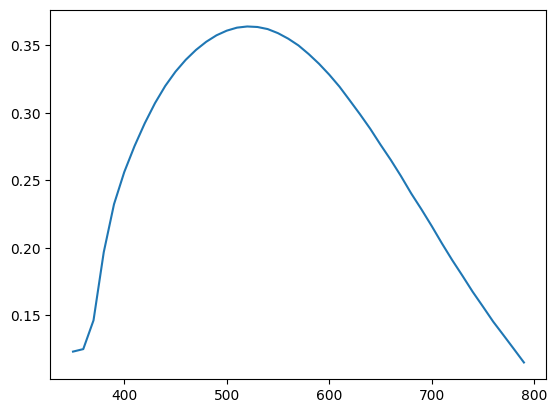

In [ ]:

from scipy.optimize import minimize as spMin
from scipy.optimize import curve_fit

## split the two input dictionaries into a list and sorted dictionary
## following the order of the function arguments in input function
def sort_dicts(floatDict, fixedDict, funcToOrganizeTo = PDE_allArgs):
    sorted_values = []
    sorted_dict = {}
    orgList = list(funcToOrganizeTo.__code__.co_varnames[:funcToOrganizeTo.__code__.co_argcount])
    for key in orgList:
        if key in floatDict:
            sorted_values.append(floatDict[key])
        elif key in fixedDict:
            sorted_dict[key] = fixedDict[key]
    return sorted_values, sorted_dict

# use this inside the wrapped PDE function.
# allows us to pass the args to PDE function with the correct format to use 'minimize' or 'curve_fit'
# merges all inputs into a single dictionary
def merge_inputs(floatList, fixedDict, keysToFill):
    inputDict = {}
    for key in keysToFill:
        if key in fixedDict:
            inputDict[key] = fixedDict[key]
        else:
            inputDict[key] = floatList.pop(0)
    return inputDict

def removeDuplicateArgs(f1, f2): # remove any args names from f1 that are also in f2
    f1Args = list(f1.__code__.co_varnames[:f1.__code__.co_argcount])
    f2Args = list(f2.__code__.co_varnames[:f2.__code__.co_argcount])
    print(f1Args)
    print(f2Args)
    return [arg for arg in f1Args if arg not in f2Args]

def wrappedPDE(floatParList, fixedParDict, wlen, theta1, FF = 0.7, pdeFunction = PDE_allArgs):
    functionArgNames = removeDuplicateArgs(pdeFunction, wrappedPDE)
    
    newInput = merge_inputs(floatParList, fixedParDict, keysToFill=functionArgNames)
    
    return pdeFunction(wlen = wlen, theta1 = theta1, FF = FF, **newInput)
    
    
## How to use wrapped PDE function
parFixed = {"Xpn":2e3, "dw_star":5e3, "ph":0.3}
parFloat = {"pe":0.6, "tOxide":90, "dp_star":4}

# lower_bounds = [bounds_dict[param][0] for param in arg_names]
# upper_bounds = [bounds_dict[param][1] for param in arg_names]
# p0 = [guess_dict[param] for param in arg_names]

pars, fixed = sort_dicts(parFloat, parFixed, funcToOrganizeTo=PDE_allArgs)
print(pars, fixed)
argList = removeDuplicateArgs(PDE_allArgs, wrappedPDE)
print(argList)
newInput = merge_inputs(pars, fixed, argList)

wlenTest = np.arange(350, 800, 10)
yTest = PDE_allArgs(wlen = wlenTest, theta1 = 0.0, FF = 0.7, **newInput)
plt.plot(wlenTest, yTest, label = "wrappedPDE")

In [ ]:
# lower_bounds = [bounds_dict[param][0] for param in arg_names]
# upper_bounds = [bounds_dict[param][1] for param in arg_names]
# p0 = [guess_dict[param] for param in arg_names]

# pars, fixed = sort_dicts(parFloat, parFixed, fitFunction_argNames)
# wrappedPDE(pars, fixed, wlen = 400, theta = 0.0, FF = 0.7, func = PDE_allArgs)

# print(fitFunction_argNames)

def PDE_minimizer_control(floatPars, fixedPars, wlenRange, thetaRange, dataFrame, func = PDE_allArgs):
    
    pars_to_change, fixedInputs = sort_dicts(floatPars, fixedPars, func.__code__.co_varnames[:func.__code__.co_argcount])
    
    thetaData = 0
    vovData = 4
    dataX = df[(df['Angle'] == thetaData) & (df['Overvoltage'] == vovData)]['Wavelength']
    dataY = df[(df['Angle'] == thetaData) & (df['Overvoltage'] == vovData)]['PDE']
    
    fitYvals = wrappedPDE(pars_to_change, fixedInputs, wlen = dataX, theta=thetaData, FF = 0.7, func = func)
    
    # spMin.minimize(fun = , x0 , args = )
    return dataX, fitYvals

# # print("fixed:", parFixed)
# # print("float:", parFloat)
# xp, yp = PDE_minimizer_control(parFloat, parFixed)
# plt.plot(xp, yp)